In [24]:
import sklearn
import numpy as np
from sklearn.svm import SVC
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import LeaveOneOut,cross_val_predict
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.cluster import KMeans, MeanShift, AffinityPropagation, SpectralClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_mutual_info_score, adjusted_rand_score,classification_report

In [25]:
iris = datasets.load_iris()
X = iris.data
Y = iris.target

## PARTIE A :

### Question A.1 et A.2

In [26]:
def analyse(X,Y):
    nb_data = len(X)
    nb_var = np.shape(X)[1]
    nb_classe = len(np.unique(Y))
    moyenne = np.mean(X,axis=0)
    ecart = np.std(X,axis=0)
    mini = np.min(X,axis=0)
    maxi = np.max(X,axis=0)

    pca = PCA()
    XPCA  = pca.fit(X).transform(X)

    lda = LDA()
    XLDA = lda.fit(X, Y).transform(X)

    plt.scatter(XPCA[:, 0], XPCA[:, 1], c=Y, cmap='viridis')
    plt.title("PCA")
    plt.show()

    plt.scatter(XLDA[:, 0], XLDA[:, 1], c=Y, cmap='viridis')
    plt.title("LDA")
    plt.show()

    return nb_data, nb_var,nb_classe, moyenne, ecart, mini, maxi

### Suite question A.2
- L'ACP est une méthode non supervisée, elle projette les données dans un espace de dimension plus petite en cherchant à maximiser la variance.
- L'ADL est une méthode supervisée, on projette aussi mais cette fois en cherchant des axes optimaux en maximisant la séparabilité entre les classes

## PARTIE B

### Question B.1

In [27]:
def kmeans_manuel(X, k):    
    indices = np.random.choice(X.shape[0], k, replace=False)
    centroides_liste = []

    for index in indices:
        point = X[index]
        centroides_liste.append(point)

    cluster = np.zeros(X.shape[0])

    for z in range(100):

        distances = np.zeros((X.shape[0], k))

        for i in range(X.shape[0]):
            point_actuel = X[i]

            for j in range(k):
                centroide_actuel = centroides_liste[j] 

                somme_des_carres = 0
                for d in range(X.shape[1]):
                    ecart = point_actuel[d] - centroide_actuel[d]
                    somme_des_carres += ecart ** 2

                distances[i][j] = somme_des_carres

        nouveaux_cluster = np.argmin(distances, axis=1)

        liste_nouveaux_centroides = []

        for c in range(k):
            if (nouveaux_cluster == c).any() :
                points = []
                for i in range(len(X)):
                    if nouveaux_cluster[i] == c:
                        points.append(X[i])
                nouveau_centre = np.array(np.mean(points, axis=0))

                liste_nouveaux_centroides.append(nouveau_centre)
            else :
                liste_nouveaux_centroides.append(centroides_liste[c]) 

        if np.array_equal(cluster, nouveaux_cluster):
            break

        cluster = nouveaux_cluster
        centroides_liste = liste_nouveaux_centroides
    return cluster

### Suite question B.1

In [28]:
print("1er lancement du KMeans Manuel pour k  = 3 :")
print(kmeans_manuel(X, 3))

print("Lancement du KMeans Sklearn pour k = 3")
kmeans = KMeans(n_clusters=3, random_state=42, n_init=100).fit(X)
nouveaux_cluster = kmeans.labels_
print(nouveaux_cluster)

1er lancement du KMeans Manuel pour k  = 3 :
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 1 1 1 1 2 1 1 1 1
 1 1 2 2 1 1 1 1 2 1 2 1 2 1 1 2 2 1 1 1 1 1 2 1 1 1 1 2 1 1 1 2 1 1 1 2 1
 1 2]
Lancement du KMeans Sklearn pour k = 3
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


Interprétation : Les deux algo sont differents ce qui est sans doute dû au choix aleatoire des centres.

### Question B.2

In [29]:
print("2eme lancement du KMeans Manuel pour k  = 3 :")
print(kmeans_manuel(X, 3))

2eme lancement du KMeans Manuel pour k  = 3 :
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 0 1 0 0 0 0
 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0
 0 1]


Interpretation : On remarque bien que les deux lancements nous renvoie des résultats differents, ce qui est bel et bien dû au choix aléatoire de nos centres

### Question B.3

In [30]:
best = -1
meilleur_k = -1
meilleur_solution = -1
for i in range(2,11):
    for j in range(10):
        cluster = kmeans_manuel(X, i)
        score = silhouette_score(X, cluster)
   
        if score > best :
            best = score
            meilleur_k = i
            meilleur_solution = cluster

print(f"Le nombre de cluster retenu est de {meilleur_k} avec score : {best}")

Le nombre de cluster retenu est de 2 avec score : 0.6810461692117462


Interpretation : La classe Y a 3 classes mais ici l'algo nous renvoie que 2 classes, c'est sans doute dû au fait qu'une classe est très loin des deux autres, tandis que les 2 autres se chevauchent, ce ci explioque pourquoi le score de Silhouette pour i=3 est plus faible que pour i=2 d'où la nouvelle séparation des classes en 2 classes seulement.

### Question B.4

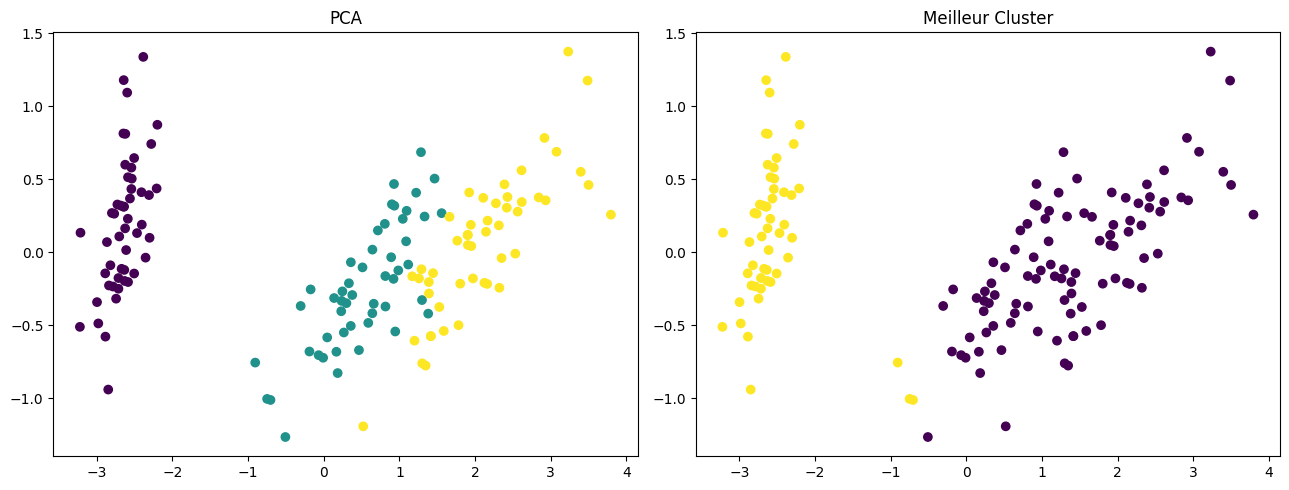

In [31]:
pca = PCA()
iris_pca = pca.fit_transform(X)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

scatter1 = ax1.scatter(iris_pca[:, 0], iris_pca[:, 1], c=Y, cmap='viridis')
ax1.set_title("PCA")

scatter2 = ax2.scatter(iris_pca[:, 0], iris_pca[:, 1], c=meilleur_solution, cmap='viridis')
ax2.set_title("Meilleur Cluster")

plt.tight_layout()
plt.show()

Interpretation : On a une meilleure visualisation de la sortie de score. En effet, on a 2 classes au lieu de 3. L'une des classes est bien separée dans les deux cas. Tandis que celles qui se chevauchent ont fusionné.

## PARTIE C :

### Question C.1

In [32]:
def Clustering_donnes_diff_algo(X,Y):

    print("\nLes etiquettes proposés par les 5 algos differents :\n")
    print("#" * 70)

    print("1er algo : KMeans Manuel")
    cluster_kmeans =  kmeans_manuel(X, len(np.unique(Y)))
    print(cluster_kmeans)
    score_interne_externe(X,Y,cluster_kmeans)

    print("2eme algo : MeanShift")
    clustering = MeanShift().fit(X)
    cluster_MeanShift = clustering.labels_
    print(cluster_MeanShift)
    score_interne_externe(X,Y,cluster_MeanShift)

    print("3eme algo : Affinity Propgation")
    clustering = AffinityPropagation(random_state=5).fit(X)
    cluster_AffinityPropagation = clustering.labels_
    print(cluster_AffinityPropagation)
    score_interne_externe(X,Y,cluster_AffinityPropagation)
    
    print("4eme algo : SpectralClustering")
    clustering = SpectralClustering(n_clusters=len(np.unique(Y)),random_state=5).fit(X,Y)
    cluster_SpectralClustering = clustering.labels_
    print(cluster_SpectralClustering)
    score_interne_externe(X,Y,cluster_SpectralClustering)
    
    print("5eme algo : DBSCAN")
    clustering = DBSCAN().fit(X)
    cluster_DBSCAN = clustering.labels_
    print(cluster_DBSCAN)
    score_interne_externe(X,Y,cluster_DBSCAN)

    return 0

In [33]:
def analyse(X,Y):
    nb_data = len(X)
    nb_var = np.shape(X)[1]
    nb_classe = len(np.unique(Y))
    moyenne = np.mean(X,axis=0)
    ecart = np.std(X,axis=0)
    mini = np.min(X,axis=0)
    maxi = np.max(X,axis=0)

    pca = PCA()
    XPCA  = pca.fit(X).transform(X)

    lda = LDA()
    XLDA = lda.fit(X, Y).transform(X)

    plt.scatter(XPCA[:, 0], XPCA[:, 1], c=Y, cmap='viridis')
    plt.title("PCA")
    plt.show()

    plt.scatter(XLDA[:, 0], XLDA[:, 1], c=Y, cmap='viridis')
    plt.title("LDA")
    plt.show()
    
    Clustering_donnes_diff_algo(X,Y)

    return nb_data, nb_var,nb_classe, moyenne, ecart, mini, maxi

### Question C.2

In [34]:
def score_interne_externe(X,Y,cluster):
    davies = davies_bouldin_score(X, cluster)
    silhouette = silhouette_score(X, cluster)
    mutual_info = adjusted_mutual_info_score(Y,cluster)
    rand_score = adjusted_rand_score(Y,cluster)

    print("\nScores Internes : \n")

    print(f"DAVIES BOULDIN SCORE : {davies}")
    print(f"SILHOUETTE SCORE : {silhouette}")

    print("\nScores Externe : \n")

    print(f"ADJ MUTUAL INFO : {mutual_info}")
    print(f"ADJ RAND SCORE : {rand_score}\n")

    print("#" * 70)

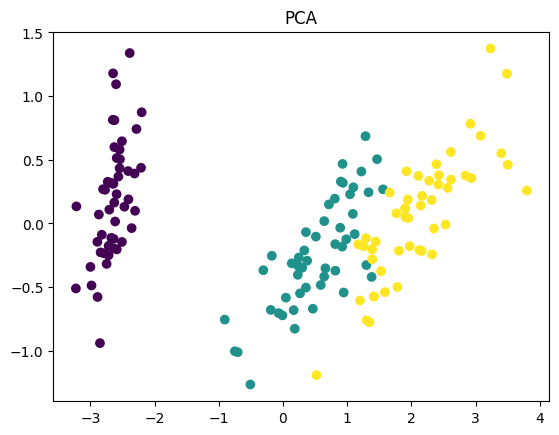

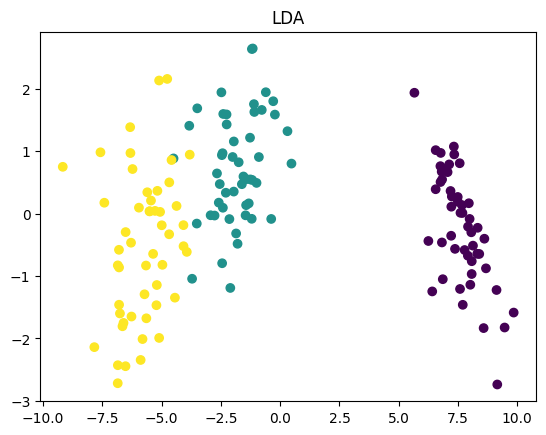


Les etiquettes proposés par les 5 algos differents :

######################################################################
1er algo : KMeans Manuel
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 1 1 1 1 2 1 1 1 1
 1 1 2 2 1 1 1 1 2 1 2 1 2 1 1 2 2 1 1 1 1 1 2 1 1 1 1 2 1 1 1 2 1 1 1 2 1
 1 2]

Scores Internes : 

DAVIES BOULDIN SCORE : 0.661971546500747
SILHOUETTE SCORE : 0.5528190123564095

Scores Externe : 

ADJ MUTUAL INFO : 0.7551191675800482
ADJ RAND SCORE : 0.7302382722834697

######################################################################
2eme algo : MeanShift
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

(150,
 4,
 3,
 array([5.84333333, 3.05733333, 3.758     , 1.19933333]),
 array([0.82530129, 0.43441097, 1.75940407, 0.75969263]),
 array([4.3, 2. , 1. , 0.1]),
 array([7.9, 4.4, 6.9, 2.5]))

In [35]:
analyse(X,Y)

### Suite question C.2
La différence entre un score interne et un score externe repose sur les données requises et l'utilité du score :
pour un score interne :
- on a seulement besoin des caractéristiques des données (donc X) et les clusters prédits, 
- on cherche à minimiser la distance intra cluster et maximiser la distance inter cluster

pour un score externe :
- on a, en plus, besoin des vraies étiquettes (Y)
- le but est de vérifier le bon étiquettage (maximiser la similarité avec la répartition réelle)

### Question C.3
Compte tenu des résultats des différentes méthodes de clustering, les méthodes qui ont les meilleurs scores et dont les scores sont les plus homogènes sont : Spectral et Kmeans manuel

## PARTIE D :

### Question D.1

In [36]:
def Leave_One_Out(X,Y):

    loo = LeaveOneOut()
    kNN_predict, erreur_knn = KNN(X,Y,loo)
    calcul("KNN", erreur_knn,Y,kNN_predict)

    gaussian_predict, erreur_guassian = gaussiannb(X,Y,loo)
    calcul("Gaussian",erreur_guassian,Y,gaussian_predict)

    MLP_predict =  cross_val_predict(MLPClassifier(max_iter=2000), X, Y, cv=loo)
    erreur_mlp = (np.sum(MLP_predict != Y) / len(Y)) * 100
    calcul("MLP", erreur_mlp,Y,MLP_predict)

    
    SVC_predict = cross_val_predict(SVC(), X, Y, cv=loo)
    erreur_svc = (np.sum(SVC_predict != Y) / len(Y)) * 100
    calcul("SVC", erreur_svc,Y,SVC_predict)

    return

In [37]:
def KNN(X,Y,loo):

    K_neigh = sklearn.neighbors.KNeighborsClassifier(n_neighbors = 1)

    y_pred_knn = cross_val_predict(K_neigh, X, Y, cv=loo)

    erreur_knn = (np.sum(y_pred_knn != Y) / len(Y)) * 100

    return y_pred_knn, erreur_knn

In [38]:
def gaussiannb(X,Y,loo) :
    gaussiannb = GaussianNB()

    y_pred_gaussiannb = cross_val_predict(gaussiannb, X, Y, cv=loo)

    err_gaussiannb = (np.sum(y_pred_gaussiannb != Y) / len(Y)) * 100

    return y_pred_gaussiannb, err_gaussiannb

In [39]:
def analyse(X,Y):
    nb_data = len(X)
    nb_var = np.shape(X)[1]
    nb_classe = len(np.unique(Y))
    moyenne = np.mean(X,axis=0)
    ecart = np.std(X,axis=0)
    mini = np.min(X,axis=0)
    maxi = np.max(X,axis=0)

    pca = PCA()
    XPCA  = pca.fit(X).transform(X)

    lda = LDA()
    XLDA = lda.fit(X, Y).transform(X)

    plt.scatter(XPCA[:, 0], XPCA[:, 1], c=Y, cmap='viridis')
    plt.title("PCA")
    plt.show()

    plt.scatter(XLDA[:, 0], XLDA[:, 1], c=Y, cmap='viridis')
    plt.title("LDA")
    plt.show()
    
    Leave_One_Out(X,Y)
    
    return

### Question D.2

In [40]:
def calcul(method, erreur,Y,predict):
    print(f"{method}\n")
    print(f"\nPourcentage d'Erreur : {erreur}\n")
    print("Rapport de classification :\n")
    print(classification_report(Y, predict))
    print("\n")
    print("#" * 70)

### Question D.3

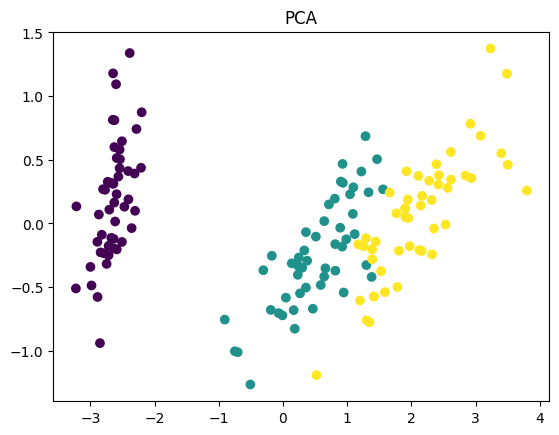

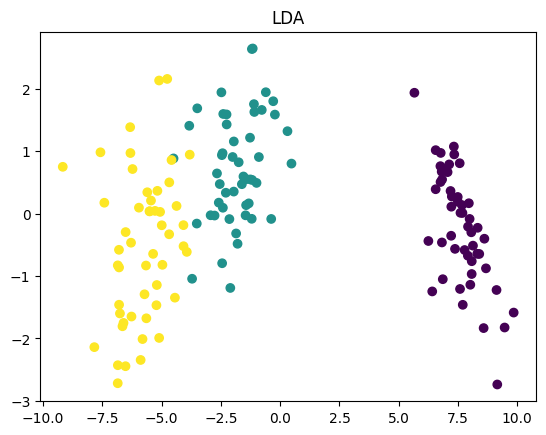

KNN


Pourcentage d'Erreur : 4.0

Rapport de classification :

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.94      0.94        50
           2       0.94      0.94      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150



######################################################################
Gaussian


Pourcentage d'Erreur : 4.666666666666667

Rapport de classification :

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.94      0.93        50
           2       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150



##################

In [41]:
analyse(X,Y)

Interprétation : La meilleure méthode de classification est le MLP (perceptron multi-couche) avec une erreur de prédiction de 2,67.

## PARTIE E :

### Question E.1
N.B. : les réponses aux questions précédentes sont toutes basées d'après les résultats sur le dataset iris

In [42]:
def analyse(X,Y):
    nb_data = len(X)
    nb_var = np.shape(X)[1]
    nb_classe = len(np.unique(Y))
    moyenne = np.mean(X,axis=0)
    ecart = np.std(X,axis=0)
    mini = np.min(X,axis=0)
    maxi = np.max(X,axis=0)

    pca = PCA()
    XPCA  = pca.fit(X).transform(X)

    lda = LDA()
    XLDA = lda.fit(X, Y).transform(X)

    plt.scatter(XPCA[:, 0], XPCA[:, 1], c=Y, cmap='viridis')
    plt.title("PCA")
    plt.show()

    plt.scatter(XLDA[:, 0], XLDA[:, 1], c=Y, cmap='viridis')
    plt.title("LDA")
    plt.show()

    Clustering_donnes_diff_algo(X,Y)
    Leave_One_Out(X,Y)

    return nb_data, nb_var,nb_classe, moyenne, ecart, mini, maxi

### Question E.2

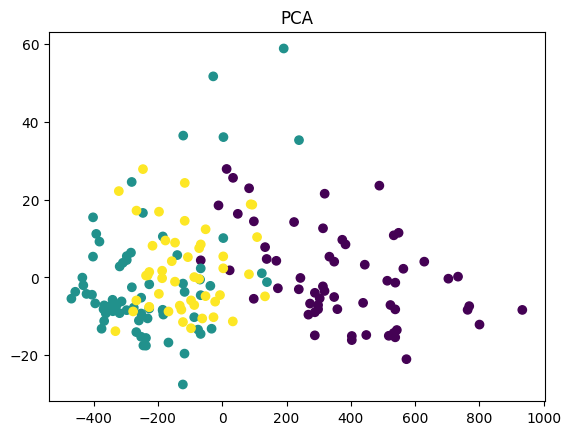

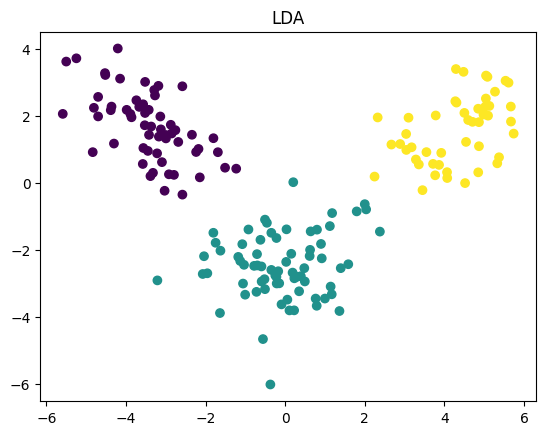


Les etiquettes proposés par les 5 algos differents :

######################################################################
1er algo : KMeans Manuel
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1 1 0 0 1 0 0 0 0 0 0 1 1
 0 0 1 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 1 2 1 2 2 1 2 2 1 1 1 2 2 0
 1 2 2 2 1 2 2 1 1 2 2 2 2 2 1 1 2 2 2 2 2 1 1 2 1 2 1 2 2 2 1 2 2 2 2 1 2
 2 1 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 1 2 2 1 1 1 1 2 2 2 1 1 2 2 1 1 2 1
 1 2 2 2 2 1 1 1 2 1 1 1 2 1 2 1 1 2 1 1 1 1 2 2 1 1 1 1 1 2]

Scores Internes : 

DAVIES BOULDIN SCORE : 0.5342431775436278
SILHOUETTE SCORE : 0.5711381937868838

Scores Externe : 

ADJ MUTUAL INFO : 0.42268666427661145
ADJ RAND SCORE : 0.37111371823084754

######################################################################
2eme algo : MeanShift
[2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 2 1 1 1 2 2 1 2 2 2 1 2 2 1 1
 2 1 1 1 2 2 0 1 2 2 1 2 2 2 2 2 2 2 2 1 2 2 0 0 0 0 0 0 0 0 0 1 0 1 0 0 1
 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 

/Volumes/Mathura-SSD/EID2/Data-Science/venv/lib/python3.9/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Volumes/Mathura-SSD/EID2/Data-Science/venv/lib/python3.9/site-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (2) found smaller than n_clusters (3). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Scores Internes : 

DAVIES BOULDIN SCORE : 0.44772255236450165
SILHOUETTE SCORE : 0.28034808703238107

Scores Externe : 

ADJ MUTUAL INFO : 0.00018503394242370846
ADJ RAND SCORE : 0.000351000351000351

######################################################################
5eme algo : DBSCAN
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -

ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)

In [43]:
wine = datasets.load_wine()
X,Y = wine.data, wine.target
print(analyse(X,Y))

### Question E.3

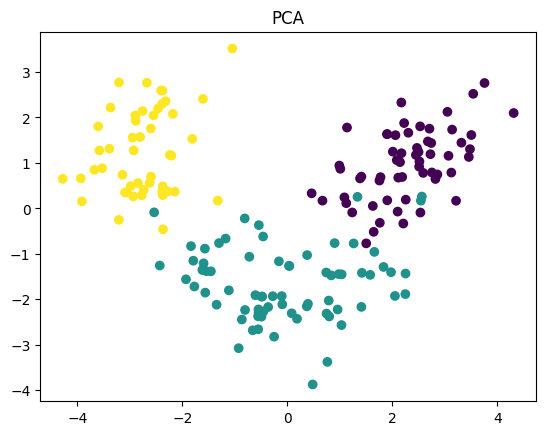

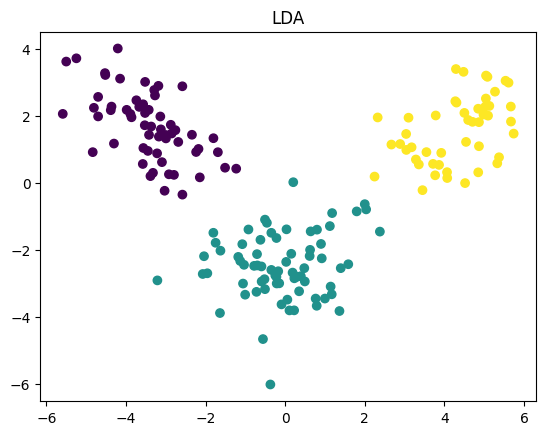

KNN


Pourcentage d'Erreur : 4.49438202247191

Rapport de classification :

              precision    recall  f1-score   support

           0       0.92      1.00      0.96        59
           1       1.00      0.89      0.94        71
           2       0.94      1.00      0.97        48

    accuracy                           0.96       178
   macro avg       0.95      0.96      0.96       178
weighted avg       0.96      0.96      0.95       178



######################################################################
Gaussian


Pourcentage d'Erreur : 2.247191011235955

Rapport de classification :

              precision    recall  f1-score   support

           0       1.00      0.97      0.98        59
           1       0.97      0.97      0.97        71
           2       0.96      1.00      0.98        48

    accuracy                           0.98       178
   macro avg       0.98      0.98      0.98       178
weighted avg       0.98      0.98      0.98       178



#####

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(analyse(X_scaled,Y))